# 🏈 NFL Data Analysis — Part 1: Understanding the Basics

This notebook is designed for **new NFL viewers**. We'll use real data from the 2021 NFL season (Weeks 1–8) to explain who plays who, how scores work, and what a typical game looks like.

---

## What you'll learn
- How many games are in a season and how they're structured by week
- Which teams appear the most in our dataset
- How scores evolve and what a typical winning margin looks like
- A quick overview of down & distance — the core mechanic of football

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Style
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12
sns.set_theme(style='whitegrid', palette='deep')

# Load data
games  = pd.read_csv('../data/games.csv')
plays  = pd.read_csv('../data/plays.csv')
players = pd.read_csv('../data/players.csv')

print(f'Games:   {len(games)} rows')
print(f'Plays:   {len(plays)} rows')
print(f'Players: {len(players)} rows')
games.head()

/home/armand/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


Games:   122 rows
Plays:   8557 rows
Players: 1679 rows


,gameId,season,week,gameDate,gameTimeEastern,homeTeamAbbr,visitorTeamAbbr
0,2021090900,2021,1,09/09/2021,20:20:00,TB,DAL
1,2021091200,2021,1,09/12/2021,13:00:00,ATL,PHI
2,2021091201,2021,1,09/12/2021,13:00:00,BUF,PIT
3,2021091202,2021,1,09/12/2021,13:00:00,CAR,NYJ
4,2021091203,2021,1,09/12/2021,13:00:00,CIN,MIN


---
## 1 — How many games per week?

> **NFL Basics:** The regular NFL season has 18 weeks. Each of the 32 teams plays once per week. Our dataset covers Weeks 1–8 of the 2021 season.

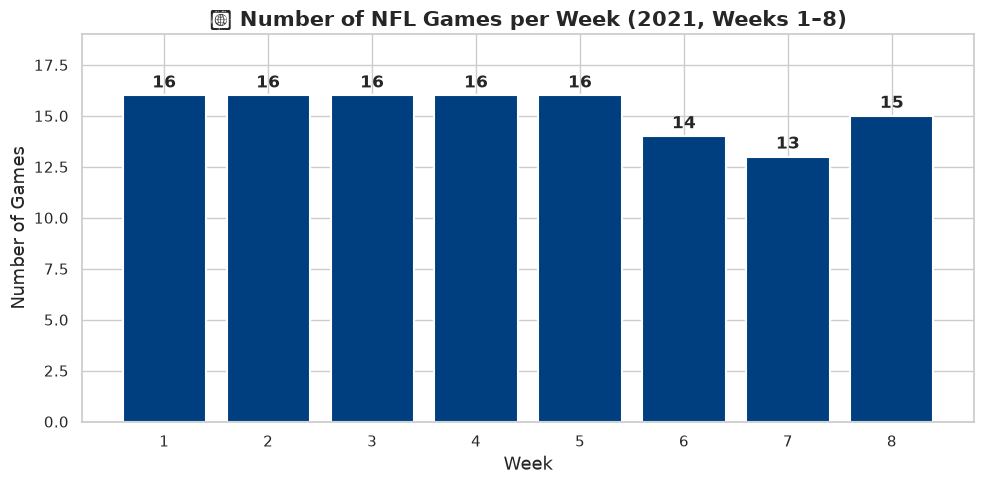

Total games in dataset: 122


In [2]:
games_per_week = games.groupby('week').size().reset_index(name='num_games')

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(games_per_week['week'], games_per_week['num_games'],
              color='#003f7f', edgecolor='white', linewidth=1.5)

for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
            str(int(bar.get_height())), ha='center', va='bottom', fontweight='bold')

ax.set_xlabel('Week', fontsize=13)
ax.set_ylabel('Number of Games', fontsize=13)
ax.set_title('📅 Number of NFL Games per Week (2021, Weeks 1–8)', fontsize=15, fontweight='bold')
ax.set_xticks(games_per_week['week'])
ax.set_ylim(0, games_per_week['num_games'].max() + 3)
plt.tight_layout()
plt.show()
print(f'Total games in dataset: {len(games)}')

---
## 2 — Which teams appear most often?

Each team plays once per week. Let's see if all 32 teams are represented equally in this dataset.

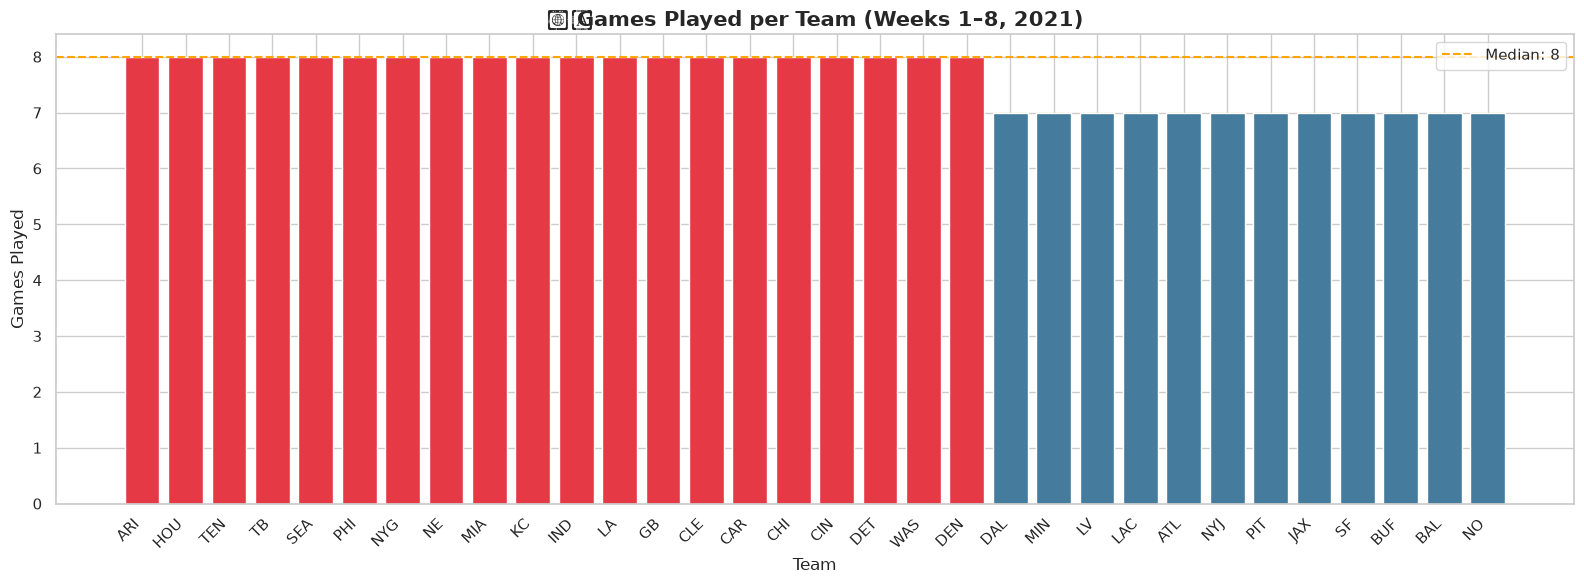

In [3]:
# Count appearances as home or visitor
home_counts    = games['homeTeamAbbr'].value_counts()
visitor_counts = games['visitorTeamAbbr'].value_counts()
total_games    = (home_counts.add(visitor_counts, fill_value=0)).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(16, 6))
colors = ['#e63946' if v == total_games.max() else '#457b9d' for v in total_games.values]
ax.bar(total_games.index, total_games.values, color=colors, edgecolor='white')

ax.set_xlabel('Team', fontsize=12)
ax.set_ylabel('Games Played', fontsize=12)
ax.set_title('🏟️ Games Played per Team (Weeks 1–8, 2021)', fontsize=15, fontweight='bold')
plt.xticks(rotation=45, ha='right')
ax.axhline(total_games.median(), color='orange', linestyle='--', label=f'Median: {total_games.median():.0f}')
ax.legend()
plt.tight_layout()
plt.show()

---
## 3 — Score margins: how much do teams win by?

> **NFL Basics:** Points are scored by touchdowns (6 pts + extra point), field goals (3 pts), or safeties (2 pts). Games are close — a 7-point margin is just one touchdown!

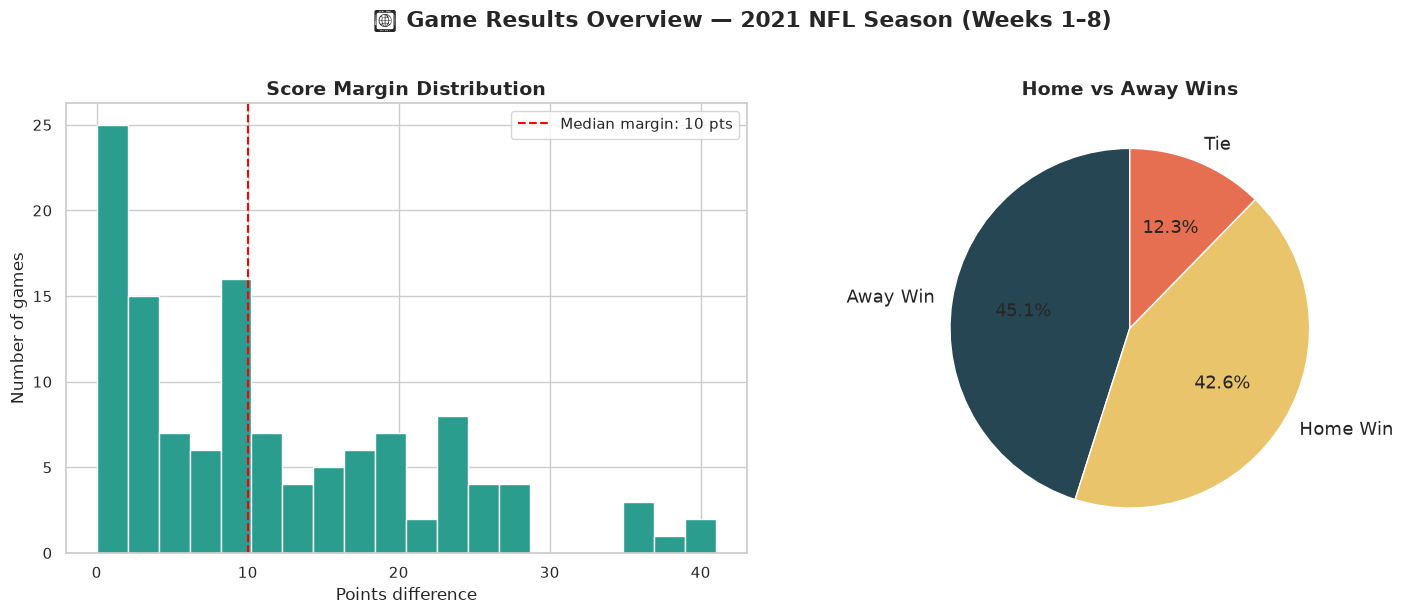

Average margin of victory: 11.7 points
Closest game: 0 pts | Biggest blowout: 41 pts


In [4]:
# Get final score per game: max preSnap scores per game ≈ final score
final_scores = plays.groupby('gameId').agg(
    home_score=('preSnapHomeScore', 'max'),
    visitor_score=('preSnapVisitorScore', 'max')
).reset_index()

final_scores['margin'] = abs(final_scores['home_score'] - final_scores['visitor_score'])
final_scores['winner'] = np.where(
    final_scores['home_score'] > final_scores['visitor_score'], 'Home Win',
    np.where(final_scores['home_score'] < final_scores['visitor_score'], 'Away Win', 'Tie')
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Histogram of margins
axes[0].hist(final_scores['margin'], bins=20, color='#2a9d8f', edgecolor='white')
axes[0].axvline(final_scores['margin'].median(), color='red', linestyle='--',
                label=f'Median margin: {final_scores["margin"].median():.0f} pts')
axes[0].set_title('Score Margin Distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Points difference')
axes[0].set_ylabel('Number of games')
axes[0].legend()

# Home vs Away wins
win_counts = final_scores['winner'].value_counts()
colors_pie = ['#264653', '#e9c46a', '#e76f51']
axes[1].pie(win_counts.values, labels=win_counts.index, autopct='%1.1f%%',
            colors=colors_pie, startangle=90, textprops={'fontsize': 13})
axes[1].set_title('Home vs Away Wins', fontsize=14, fontweight='bold')

plt.suptitle('🏆 Game Results Overview — 2021 NFL Season (Weeks 1–8)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print(f'Average margin of victory: {final_scores["margin"].mean():.1f} points')
print(f'Closest game: {final_scores["margin"].min()} pts | Biggest blowout: {final_scores["margin"].max()} pts')

---
## 4 — Downs and Distance: The Core Mechanic of Football

> **NFL Basics:** A team has **4 attempts (downs)** to advance the ball 10 yards. If they succeed, they get 4 new downs. If not, the other team takes possession. 1st & 10 is the most common situation — a fresh set of downs with 10 yards to go.

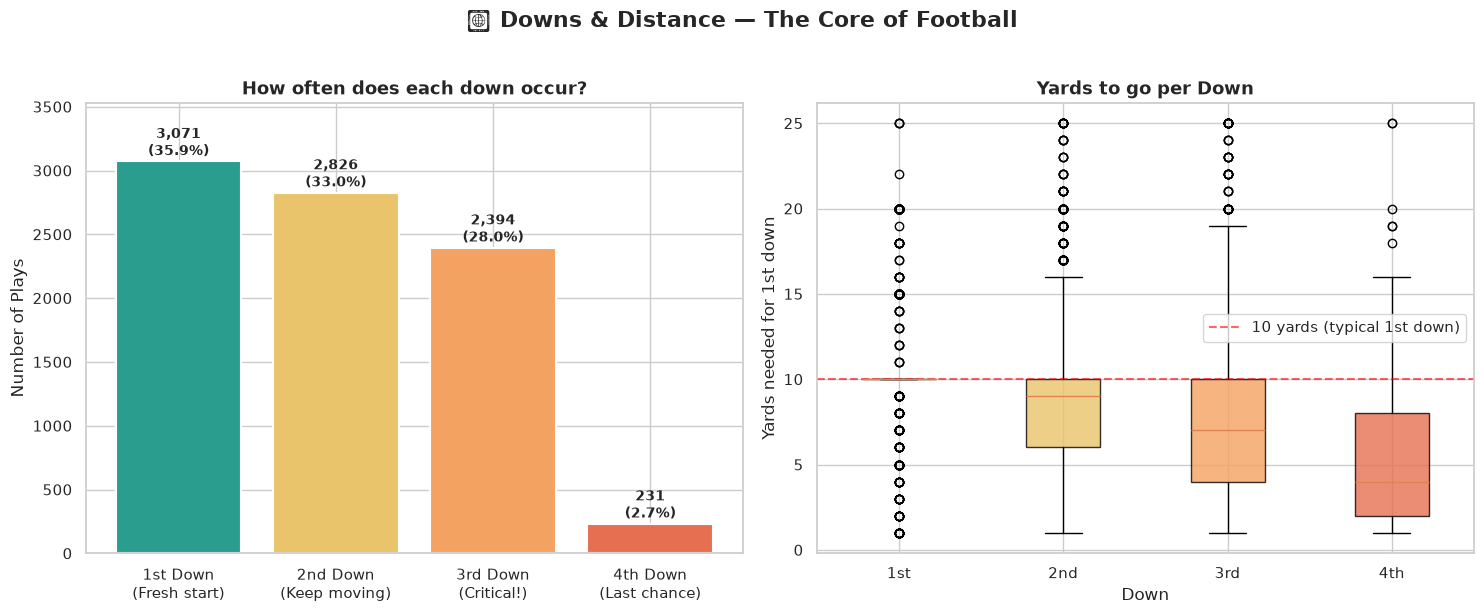

In [5]:
# Distribution of down situations (downs 1-4; a handful of plays have no standard down)
down_counts = plays[plays['down'].between(1, 4)]['down'].value_counts().sort_index()
down_labels = {1: '1st Down\n(Fresh start)', 2: '2nd Down\n(Keep moving)', 
               3: '3rd Down\n(Critical!)', 4: '4th Down\n(Last chance)'}

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Down frequency
bar_colors = ['#2a9d8f', '#e9c46a', '#f4a261', '#e76f51']
bars = axes[0].bar([down_labels[d] for d in down_counts.index], down_counts.values,
                   color=bar_colors, edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, down_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
                 f'{val:,}\n({val/len(plays)*100:.1f}%)',
                 ha='center', fontsize=10, fontweight='bold')
axes[0].set_title('How often does each down occur?', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Number of Plays')
axes[0].set_ylim(0, down_counts.max() * 1.15)

# Yards to go distribution
ytg_data = [plays[plays['down'] == d]['yardsToGo'].clip(0, 25) for d in [1, 2, 3, 4]]
bplot = axes[1].boxplot(ytg_data, patch_artist=True, notch=False)
axes[1].set_xticks([1, 2, 3, 4])
axes[1].set_xticklabels(['1st', '2nd', '3rd', '4th'])
for patch, color in zip(bplot['boxes'], bar_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)
axes[1].axhline(10, color='red', linestyle='--', alpha=0.6, label='10 yards (typical 1st down)')
axes[1].set_title('Yards to go per Down', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Down')
axes[1].set_ylabel('Yards needed for 1st down')
axes[1].legend()

plt.suptitle('📏 Downs & Distance — The Core of Football', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## 5 — Play Results: How many yards does a typical play gain?

> **Context:** To sustain a drive and eventually score, offenses need ~3.3 yards per play on average. A big play (15+ yards) is a game-changer.

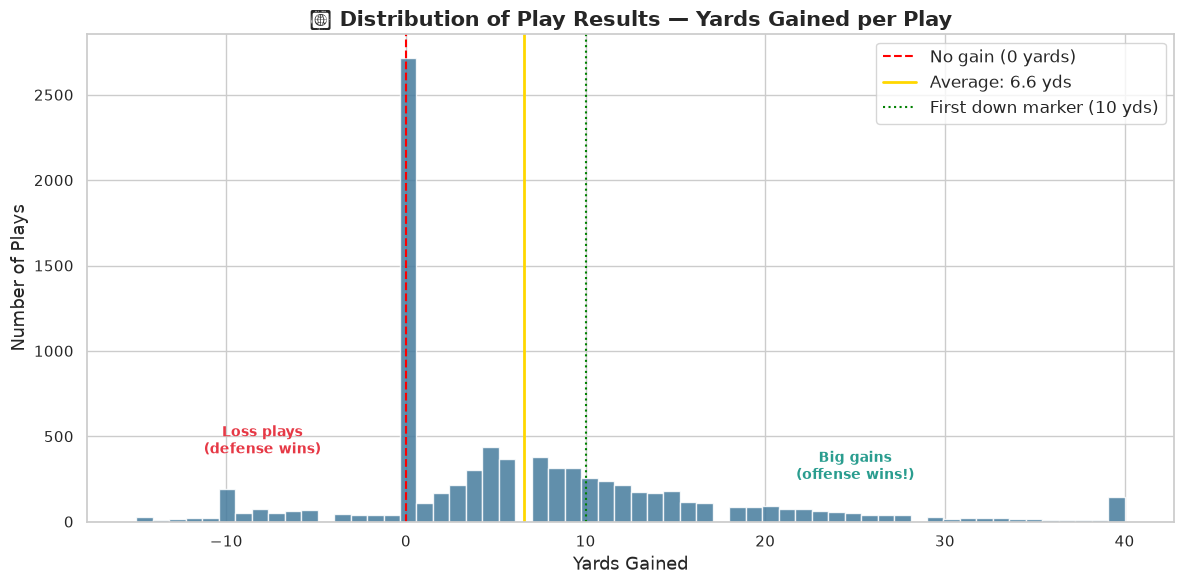

Plays that gained yards:       59.4%
Plays that earned a 1st down:  35.4%
Average gain per play:          6.56 yards


In [6]:
# Filter out extreme outliers (penalties can inflate values)
play_results = plays['playResult'].clip(-15, 40)

fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(play_results, bins=60, color='#457b9d', edgecolor='white', alpha=0.85)
ax.axvline(0,  color='red',    linestyle='--', linewidth=1.5, label='No gain (0 yards)')
ax.axvline(plays['playResult'].mean(), color='gold', linestyle='-',
           linewidth=2, label=f'Average: {plays["playResult"].mean():.1f} yds')
ax.axvline(10, color='green',  linestyle=':', linewidth=1.5, label='First down marker (10 yds)')

ax.set_xlabel('Yards Gained', fontsize=13)
ax.set_ylabel('Number of Plays', fontsize=13)
ax.set_title('📊 Distribution of Play Results — Yards Gained per Play', fontsize=15, fontweight='bold')
ax.legend(fontsize=12)

# Annotations
ax.annotate('Loss plays\n(defense wins)', xy=(-8, 400), fontsize=10, color='#e63946',
            fontweight='bold', ha='center')
ax.annotate('Big gains\n(offense wins!)', xy=(25, 250), fontsize=10, color='#2a9d8f',
            fontweight='bold', ha='center')

plt.tight_layout()
plt.show()

pct_positive = (plays['playResult'] > 0).mean() * 100
pct_first_down = (plays['playResult'] >= plays['yardsToGo']).mean() * 100
print(f'Plays that gained yards:       {pct_positive:.1f}%')
print(f'Plays that earned a 1st down:  {pct_first_down:.1f}%')
print(f'Average gain per play:          {plays["playResult"].mean():.2f} yards')

---
## Summary

| Insight | Key Takeaway |
|---|---|
| 122 games across 8 weeks | ~15 games every Sunday |
| Home teams win ~55% of the time | Home field advantage is real |
| Median margin of victory ~10 pts | Games are competitive — one TD can change everything |
| 1st down accounts for ~40% of plays | Offenses that convert often stay in control |
| Average gain: ~5.5 yards | Big plays (15+ yds) are rare but pivotal |

**➡️ Next up:** `02_offensive_strategies.ipynb` — dive into passing, formations, and QB performance.